
<div align="center">
  <img src="cover.png" width="75%">
</div>


<div style="background-color:#E0F2FE;
            padding:15px;
            border-left:6px solid #0284C7;
            border-radius:8px;">
  <h2 style="color:#075985; margin:0;">
    Introduction
  </h2>

</div>

This notebook compares a conventional neural network (NN) with a physics-informed neural network (PINN) for reconstructing the expansion history in a flat ΛCDM cosmology. It includes controlled synthetic experiments with and without Gaussian noise, followed by an exploratory fit to cosmic-chronometer measurements of H(z).

- Reconstruct the cosmic expansion history using neural networks.

- Investigate the role of physical constraints in PINN training.

- Compare NN and PINN predictions against the reference cosmological model.

- Explore the reconstruction using observational H(z) measurements.


<div style="background:#E0F2FE; padding:12px 16px;
            border:1px solid #0284C7; border-radius:8px;">
  <h2 style="color:#166534; margin:0;">
   📚 Import Libraries
  </h2>
</div>

In [1]:
import torch 
import torch.nn as nn 
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd

<div style="background:#DCFCE7; padding:14px;
            border-left:6px solid #16A34A;
            border-radius:8px;">
  <h2 style="color:#166534; margin:0;">
    Baseline Neural Network of ΛCDM Expansion History
  </h2>
</div>

In this section, a conventional feed-forward neural network is employed as a baseline model to approximate the cosmological expansion  
history H(z) in a flat ΛCDM cosmological model. Synthetic target data have been generated on the analytical relationship
$$
H(z) = \sqrt{\Omega_m(1+z)^3 + (1-\Omega_m)}
$$
where $ \Omega_m = 0.3$

<br><br>

In [2]:
torch.manual_seed(2)
z = torch.linspace(0,2,1000).reshape(-1,1)

omega_m = 0.3
class ΛCDM_nn(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(1,19)
        self.tanh = nn.Tanh()
        self.layer2 = nn.Linear(19,1)

    def forward(self,z):
        z = self.layer1(z)
        z = self.tanh(z)
        z = self.layer2(z)
        return z
        
model_nn = ΛCDM_nn()
optimizer_nn = torch.optim.Adam(model_nn.parameters(), lr=0.01)
H_true = torch.sqrt(omega_m * (1 + z)**3 + (1-omega_m))

for epoch in range(1000):
    H_pred = model_nn(z)
    loss_data_nn = torch.mean((H_true - H_pred)**2)
    optimizer_nn.zero_grad()
    loss_data_nn.backward()
    optimizer_nn.step()
    if epoch %100 ==0:
        print(f"epoch: {epoch:4d} | " 
              f"L_data: {loss_data_nn.item()}")

epoch:    0 | L_data: 2.3639535903930664
epoch:  100 | L_data: 0.013560919091105461
epoch:  200 | L_data: 0.008839094080030918
epoch:  300 | L_data: 0.005855068098753691
epoch:  400 | L_data: 0.0037093982100486755
epoch:  500 | L_data: 0.002053384203463793
epoch:  600 | L_data: 0.0008979974081739783
epoch:  700 | L_data: 0.0003048685030080378
epoch:  800 | L_data: 9.96821909211576e-05
epoch:  900 | L_data: 4.9195936298929155e-05


In [3]:
print('MSE:', loss_data_nn.item())

MSE: 3.8198202673811466e-05


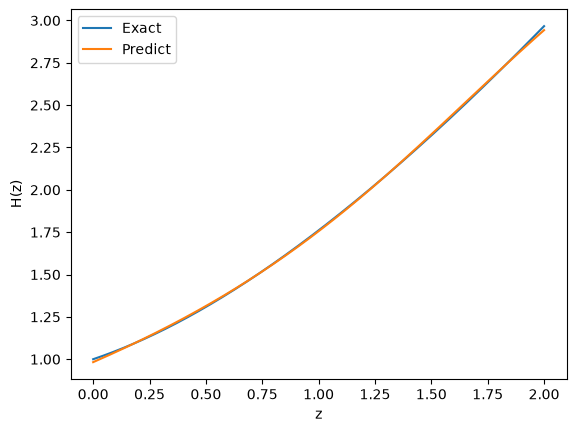

In [4]:
plt.plot(z.numpy(), H_true.numpy(), label='Exact')
plt.plot(z.numpy(), H_pred.detach().numpy(), label='Predict')
plt.xlabel('z')
plt.ylabel('H(z)')
plt.legend()

plt.show()

- At this state, no physical differential equations or cosmological parameter inferences are incorporated into the loss function. The aim of this experiment  
is to establish a purely data-driven baseline against which the "Physics-Informed Neural Network" to be employed later—can be compared.

- Following training, the predicted expansion history is compared with the analytical solution of the ΛCDM model. The close agreement between these two   curves demonstrates that the neural network is capable of approximating the system's expansion history using "clean" (noise-free) synthetic data.

<br><br>

<div style="background:#DCFCE7; padding:14px;
            border-left:6px solid #16A34A;
            border-radius:8px;">
  <h2 style="color:#166534; margin:0;">
    Baseline Neural Network with Noise Data
  </h2>
</div>

In this section, the conventional neural network model is evaluated in the presence of observational noise. Starting with the ΛCDM expansion history, Gaussian noise is added to generate synthetic observations:
$$
H_{obs}(z)=H_{true}(z)+ϵ,
$$
where $ϵ∼\mathcal{N}(0,σ2).$ A noise standard deviation of $\sigma=0.05$ is used in this experiment.   
The neural network is trained only against the noisy observations using the mean squared error.
<br><br>

In [5]:
torch.manual_seed(2)
z = torch.linspace(0,2,1000).reshape(-1,1)

omega_m = 0.3
class ΛCDM_nn_noise(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(1,19)
        self.tanh = nn.Tanh()
        self.layer2 = nn.Linear(19,1)

    def forward(self,z):
        z = self.layer1(z)
        z = self.tanh(z)
        z = self.layer2(z)
        return z
model_nn_noise = ΛCDM_nn_noise()
optimizer_nn_noise = torch.optim.Adam(model_nn_noise.parameters(), lr=0.01)
H_true = torch.sqrt(omega_m * (1 + z)**3 + (1-omega_m))
noise_std = 0.05
noise = noise_std *torch.randn_like(H_true)
H_obs = H_true + noise

for epoch in range(1000):
    H_pred = model_nn_noise(z)
    loss_data_nn_noise = torch.mean((H_obs - H_pred)**2)
    optimizer_nn_noise.zero_grad()
    loss_data_nn_noise.backward()
    optimizer_nn_noise.step()
    if epoch %100 ==0:
        print(
            f"epoch: {epoch:4d} | " 
            f"L_data: {loss_data_nn_noise.item()}")

epoch:    0 | L_data: 2.3666396141052246
epoch:  100 | L_data: 0.016311433166265488
epoch:  200 | L_data: 0.011481515131890774
epoch:  300 | L_data: 0.00841858796775341
epoch:  400 | L_data: 0.006199133116751909
epoch:  500 | L_data: 0.004470651503652334
epoch:  600 | L_data: 0.0032670816872268915
epoch:  700 | L_data: 0.0026609033811837435
epoch:  800 | L_data: 0.002458080416545272
epoch:  900 | L_data: 0.0024101787712424994


In [6]:
mse_obs = torch.mean((H_pred - H_obs)**2)
mse_true = torch.mean((H_pred - H_true)**2)
print("MSE vs observed:", mse_obs.item())
print("MSE vs true:", mse_true.item())

MSE vs observed: 0.0024001593701541424
MSE vs true: 3.740055035450496e-05


- In this scenario, the analytical solution $H_{true}(z)$ is preserved separately and is not used as a training target. This enables an independent evaluation of the final model against the underlying noise-free solution.

- When faced with noisy observations, the trained network achieves an MSE of approximately $2.4\times10^{-3}$, whereas its MSE relative to the underlying noise-free solution is approximately $3.7\times10^{-5}$.

- This result indicates that the neural network does not reproduce all the random fluctuations present in the noisy data; instead, it learns a relatively smooth approximation of the underlying expansion history. This experiment provides a crucial basis for evaluating whether imposing physical constraints via a Physics-Informed Neural Network (PINN) can further enhance robustness against noisy data.
<br><br>

<div style="background:#DCFCE7; padding:14px;
            border-left:6px solid #16A34A;
            border-radius:8px;">
  <h2 style="color:#166534; margin:0;">
    Physics-Informed Neural Network (PINN) for ΛCDM Expansion History
  </h2>
</div>


- In this section, a Physics-Informed Neural Network (PINN) is developed to model the cosmic expansion history, $H(z)$, incorporating the dynamics of the $\Lambda$CDM model (as the baseline model) into the training process.

- Unlike conventional neural networks, the PINN does not rely solely on a data-fitting loss function; instead, the training objective comprises a combination of the physical residual, initial conditions, and the data-fitting term.

- By differentiating the Hubble parameters, we obtain
$$
2H\frac{dH}{dz} -3\Omega_m (1+z)^2=0
$$
- The neural network predicts $H_\theta(z)$, and automatic differentiation is used to compute $dH_\theta/dz$.
  <br><br>

In [7]:
torch.manual_seed(2)
z = torch.linspace(0,2,1000).reshape(-1,1)
z.requires_grad_(True)
omega_m = 0.3
class ΛCDM_pinn(nn.Module):
    def __init__(self):
        super().__init__()
        self.omega_m2 = nn.Parameter(torch.tensor(0.2))
        self.layer1 = nn.Linear(1,19)
        self.tanh = nn.Tanh()
        self.layer2 = nn.Linear(19,1)

    def forward(self,z):
        z = self.layer1(z)
        z = self.tanh(z)
        z = self.layer2(z)
        return z

model_pinn = ΛCDM_pinn()
optimizer_pinn = torch.optim.Adam(model_pinn.parameters(), lr =0.01)
z0 = torch.tensor([[0.0]])
H0 = torch.tensor([[1.0]]) 
H_true = torch.sqrt(omega_m * (1 + z)**3 + (1-omega_m)).detach()
lambda_r = 1.0
lambda_ic = 1.0
lambda_data = 2.0

results = []
for epoch in range(1000):
    H_pred = model_pinn(z)
    dH_dz = torch.autograd.grad(
        outputs = H_pred,
        inputs = z,
        create_graph=True,
        grad_outputs=torch.ones_like(H_pred))[0]
    residual = 2 * H_pred * dH_dz - 3 * model_pinn.omega_m2 * (1+z)**2
    loss_r = torch.mean(residual**2)
    H0_pred = model_pinn(z0)
    loss_ic = torch.mean((H0_pred-H0)**2)
    loss_data = torch.mean((H_pred - H_true)**2)
    loss_pinn = lambda_r * loss_r + lambda_ic * loss_ic + lambda_data * loss_data
    optimizer_pinn.zero_grad()
    loss_pinn.backward()
    optimizer_pinn.step()
    if epoch %200 == 0:
        results.append({
            "epoch": epoch,
            "L_total": loss_pinn.item(),
            "L_r": loss_r.item(),
            "L_ic": loss_ic.item(),
            "L_data": loss_data.item(),
            "Omega_m": model_pinn.omega_m2.item()    
        })

results_pinn =  pd.DataFrame(results)
print(results_pinn)
        
  

   epoch    L_total       L_r          L_ic    L_data   Omega_m
0      0  13.632625  8.408520  4.961973e-01  2.363954  0.190000
1    200   0.147754  0.052735  9.363289e-03  0.042828  0.190604
2    400   0.006670  0.005850  1.837023e-05  0.000401  0.289932
3    600   0.000854  0.000823  7.045128e-07  0.000015  0.298170
4    800   0.000196  0.000193  1.800015e-07  0.000001  0.299420


In [8]:
model_pinn.omega_m2.item()

0.299746036529541

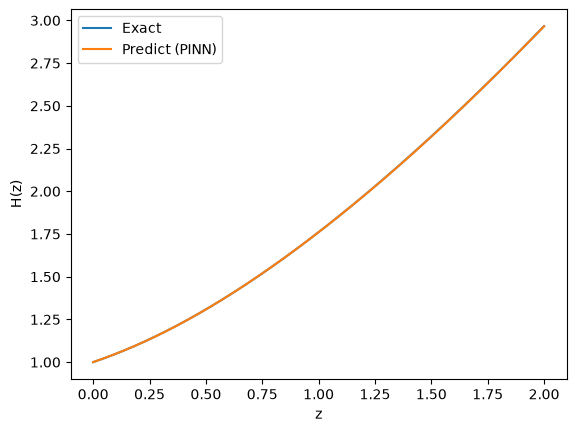

In [9]:
z_test = torch.linspace(0,2,1000).reshape(-1,1)
with torch.no_grad():
    H_pred = model_pinn(z_test)
plt.plot(z_test.numpy(), H_true.numpy(), label='Exact')
plt.plot(z_test.numpy(), H_pred.numpy(), label='Predict (PINN)')
plt.xlabel('z')
plt.ylabel('H(z)')
plt.legend()

plt.show()

- In this case, in addition to learning the function $H(z)$, the model also treats $\Omega_m$ as a learnable parameter. Therefore, PINNs can be used not only for function approximation but also for inference of cosmological parameters.

- This formulation provides a physics-based alternative to purely data-driven neural networks and enables an investigation of how physical constraints influence the reconstruction of the cosmic expansion history.

  <br><br>

<div style="background:#DCFCE7; padding:14px;
            border-left:6px solid #16A34A;
            border-radius:8px;">
  <h2 style="color:#166534; margin:0;">
    PINN Performance under Different Noisy Levels
  </h2>
</div>

<div align="left">
  <span style="
    display: inline-block;
    background-color: #E0F2FE;
    color: #0369A1;
    border: 1px solid #38BDF8;
    padding: 5px 12px;
    border-radius: 6px;
    font-weight: bold;
  ">
    $\sigma = 0.05$
  </span>
</div>

In [10]:
torch.manual_seed(2)
z = torch.linspace(0,2,1000).reshape(-1,1)
z.requires_grad_(True)
omega_m = 0.3
H_true =  torch.sqrt(omega_m * (1 + z)**3 + (1-omega_m))
noise_std = 0.05
noise = noise_std * torch.randn_like(H_true)
H_obs = H_true + noise
H_true = H_true.detach()
H_obs = H_obs.detach()

class ΛCDM_pinn_noise(nn.Module):
    def __init__(self):
        super().__init__()
        self.omega_m2 = nn.Parameter(torch.tensor(0.5))
        self.layer1 = nn.Linear(1,19)
        self.tanh = nn.Tanh()
        self.layer2 = nn.Linear(19,1)

    def forward(self,z):
        z = self.layer1(z)
        z = self.tanh(z)
        z = self.layer2(z)
        return z

model_pinn_noise = ΛCDM_pinn_noise()
optimizer_pinn_noise = torch.optim.Adam(model_pinn_noise.parameters(), lr =0.01)
z0 = torch.tensor([[0.0]])
H0 = torch.tensor([[1.0]]) 
lambda_r = 1.0
lambda_ic = 1.0
lambda_data = 2

results=[]
for epoch in range(1000):
    H_pred = model_pinn_noise(z)
    dH_dz = torch.autograd.grad(
        outputs = H_pred,
        inputs = z,
        create_graph=True,
        grad_outputs=torch.ones_like(H_pred))[0]
    residual = 2 * H_pred * dH_dz - 3 * model_pinn_noise.omega_m2 * (1+z)**2 
    loss_r = torch.mean(residual**2)
    H0_pred = model_pinn_noise(z0)
    loss_ic = torch.mean((H0_pred-H0)**2)
    loss_data = torch.mean((H_pred - H_obs)**2)
    loss_pinn_noise = lambda_r * loss_r + lambda_ic * loss_ic + lambda_data * loss_data
    optimizer_pinn_noise.zero_grad()
    loss_pinn_noise.backward()
    optimizer_pinn_noise.step()
    if epoch %200 == 0:
         results.append({
        "epoch" : epoch,
        "L_total": loss_pinn_noise.item(),
        "L_r": loss_r.item(),
        "L_ic": loss_ic.item(),
        "L_data": loss_data.item(),
        "Omega_m": model_pinn_noise.omega_m2.item()
         })
    
results_pinn_noise = pd.DataFrame(results)
print(results_pinn_noise)


   epoch    L_total        L_r      L_ic    L_data   Omega_m
0      0  64.459076  52.498520  1.180970  5.389795  0.490000
1    200   0.732972   0.156335  0.093722  0.241458  0.047381
2    400   0.156278   0.026210  0.016950  0.056559  0.178824
3    600   0.028057   0.009748  0.000948  0.008680  0.259109
4    800   0.007174   0.001388  0.000045  0.002870  0.289547


In [11]:
omega_m_est = model_pinn_noise.omega_m2.item()

print("True Omega_m =", omega_m)
print("Estimated Omega_m =", omega_m_est)
print(
    "Absolute error =",
    abs(omega_m_est - omega_m)
)

True Omega_m = 0.3
Estimated Omega_m = 0.2987107038497925
Absolute error = 0.0012892961502075084


<div align="left">
  <span style="
    display: inline-block;
    background-color: #E0F2FE;
    color: #0369A1;
    border: 1px solid #38BDF8;
    padding: 5px 12px;
    border-radius: 6px;
    font-weight: bold;
  ">
    $\sigma$ = [0%, 2%,  5%, 10%]
  </span>
</div>

In [12]:
torch.manual_seed(2)
z = torch.linspace(0,2,1000).reshape(-1,1)
z.requires_grad_(True)

class ΛCDM_pinn_noise2(nn.Module):
    def __init__(self):
        super().__init__()
        self.omega_m2 = nn.Parameter(torch.tensor(0.5))
        self.layer1 = nn.Linear(1,19)
        self.tanh = nn.Tanh()
        self.layer2 = nn.Linear(19,1)

    def forward(self,z):
        z = self.layer1(z)
        z = self.tanh(z)
        z = self.layer2(z)
        return z

omega_m = 0.3
H_true =  torch.sqrt(omega_m * (1 + z)**3 + (1-omega_m)).detach()
noise_levels = [0.0, 0.02, 0.05, 0.10]
z0 = torch.tensor([[0.0]])
H0 = torch.tensor([[1.0]]) 
lambda_r = 1.0
lambda_ic = 1.0
lambda_data = 1

for noise_std in noise_levels:
    noise = noise_std * torch.randn_like (H_true)
    H_obs = H_true + noise
    model_pinn_noise2 = ΛCDM_pinn_noise2()
    optimizer_pinn_noise2 = torch.optim.Adam(model_pinn_noise2.parameters(), lr =0.01)
    for epoch in range(1000):
        H_pred = model_pinn_noise2(z)
        dH_dz = torch.autograd.grad(
            outputs = H_pred,
            inputs = z,
            create_graph=True,
            grad_outputs=torch.ones_like(H_pred))[0]
        residual = 2 * H_pred * dH_dz - 3 * model_pinn_noise2.omega_m2 * (1+z)**2 
        loss_r = torch.mean(residual**2)
        H0_pred = model_pinn_noise2(z0)
        loss_ic = torch.mean((H0_pred-H0)**2)
        loss_data = torch.mean((H_pred - H_obs)**2)
        loss_pinn_noise2 = lambda_r * loss_r + lambda_ic * loss_ic + lambda_data * loss_data
        optimizer_pinn_noise2.zero_grad()
        loss_pinn_noise2.backward()
        optimizer_pinn_noise2.step()
        if epoch %200 == 0:
            print(
                 f"epoch= {epoch:4d}|" ,
                 f"total = {loss_pinn_noise2.item():.3f}|",
                 f"L_r = {loss_r.item():.5f}|",
                 f"L_ic = {loss_ic.item():.5f}|",
                 f"L_data = {loss_data.item()}") 
    print( f"Noise = {noise_std*100:.0f}%  "
           f"Omega_m_true={omega_m:.1f} "
           f"Omega_m = {model_pinn_noise2.omega_m2.item():.4f}")
    print("-" * 60)
    
    

epoch=    0| total = 59.053| L_r = 52.49852| L_ic = 1.18097| L_data = 5.37356424331665
epoch=  200| total = 0.585| L_r = 0.06868| L_ic = 0.09839| L_data = 0.4182206094264984
epoch=  400| total = 0.368| L_r = 0.12787| L_ic = 0.02060| L_data = 0.21996796131134033
epoch=  600| total = 0.079| L_r = 0.01496| L_ic = 0.00652| L_data = 0.05797535926103592
epoch=  800| total = 0.018| L_r = 0.00761| L_ic = 0.00050| L_data = 0.009872392751276493
Noise = 0%  Omega_m_true=0.3 Omega_m = 0.2824
------------------------------------------------------------
epoch=    0| total = 65.266| L_r = 55.23375| L_ic = 2.95004| L_data = 7.081953048706055
epoch=  200| total = 0.237| L_r = 0.07906| L_ic = 0.01245| L_data = 0.14572158455848694
epoch=  400| total = 0.095| L_r = 0.01598| L_ic = 0.00883| L_data = 0.0706821084022522
epoch=  600| total = 0.040| L_r = 0.01337| L_ic = 0.00210| L_data = 0.024080347269773483
epoch=  800| total = 0.020| L_r = 0.01178| L_ic = 0.00039| L_data = 0.00787175539880991
Noise = 2%  Om

- To investigate the sensitivity of the PINN model to observational uncertainties, the model is evaluated under several noise levels: 0%, 2% and 5% 10% .
- For each noise level, Gaussian noise is added to the theoretical ${\Lambda} CDM$ expansion history, and a Physics-Informed Neural Network (PINN) is independently initialized and trained. To ensure consistency and facilitate a fair comparison, the same network architecture and optimization settings are used across all experiments.

- The inferred value of $\Omega_m $ is then compared with its true value, $\Omega_m = 0.3$. This experiment is designed to investigate the impact of increasing observational noise on the reconstruction of the H(z) function and the accuracy of cosmological parameter inference.

- In particular, comparing the noise-free and noisy cases provides a controlled test of the robustness and stability of the proposed physics-informed approach.

<br><br>

<div style="background:#DCFCE7; padding:14px;
            border-left:6px solid #16A34A;
            border-radius:8px;">
  <h2 style="color:#166534; margin:0;">
    Comparision: NN vs PINN
  </h2>
</div>

In [13]:
torch.manual_seed(2)
z = torch.linspace(0,2,1000).reshape(-1,1)

omega_m = 0.3
class ΛCDM_nn_noise(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(1,19)
        self.tanh = nn.Tanh()
        self.layer2 = nn.Linear(19,1)

    def forward(self,z):
        z = self.layer1(z)
        z = self.tanh(z)
        z = self.layer2(z)
        return z
model_nn_compare = ΛCDM_nn_noise()
optimizer_nn_compare = torch.optim.Adam(model_nn_compare.parameters(), lr=0.01)
H_true = torch.sqrt(omega_m * (1 + z)**3 + (1-omega_m))
noise_std = 0.05
noise = noise_std *torch.randn_like(H_true)
H_obs = H_true + noise

for epoch in range(1000):
    H_pred_nn = model_nn_compare(z)
    loss_data = torch.mean((H_pred_nn - H_obs)**2)
    optimizer_nn_compare.zero_grad()
    loss_data.backward()
    optimizer_nn_compare.step()
    if epoch %100 ==0:
        print(
            f"epoch: {epoch:4d} |"
            f"Loss_nn :{loss_data.item():.5f} ")
        

epoch:    0 |Loss_nn :2.36664 
epoch:  100 |Loss_nn :0.01631 
epoch:  200 |Loss_nn :0.01148 
epoch:  300 |Loss_nn :0.00842 
epoch:  400 |Loss_nn :0.00620 
epoch:  500 |Loss_nn :0.00447 
epoch:  600 |Loss_nn :0.00327 
epoch:  700 |Loss_nn :0.00266 
epoch:  800 |Loss_nn :0.00246 
epoch:  900 |Loss_nn :0.00241 


In [14]:
with torch.no_grad():
    H_pred_nn =  model_nn_compare(z)
    mse_nn_obs = torch.mean((H_pred_nn-H_obs)**2)
    mse_nn_true = torch.mean((H_pred_nn - H_true)**2)

print(f"NN MSE vs observed data: {mse_nn_obs.item()} " , "\n"
      f"NN MSE vs true solution: {mse_nn_true.item()} " )

NN MSE vs observed data: 0.0024001130368560553  
NN MSE vs true solution: 3.739321982720867e-05 


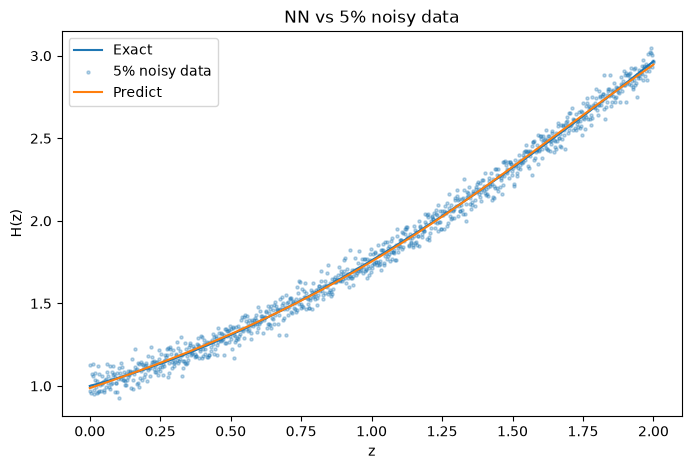

In [15]:
plt.figure(figsize=(8,5))

plt.plot (z.detach(), H_true.detach(), label = 'Exact')

plt.scatter (z.detach(), H_obs.detach(), s = 5 , alpha = 0.3, label = '5% noisy data')

plt.plot (z.detach(), H_pred_nn.detach(), label = 'Predict')
plt.xlabel('z')
plt.ylabel('H(z)')
plt.title('NN vs 5% noisy data')
plt.legend()

plt.show()

In [16]:
torch.manual_seed(2)
z = torch.linspace(0,2,1000).reshape(-1,1)
z.requires_grad_(True)
omega_m = 0.3
H_true =  torch.sqrt(omega_m * (1 + z)**3 + (1-omega_m))
noise_std = 0.05
noise = noise_std * torch.randn_like(H_true)
H_obs = H_true + noise
H_true = H_true.detach()
H_obs = H_obs.detach()

class ΛCDM_pinn_compare(nn.Module):
    def __init__(self):
        super().__init__()
        self.omega_m2 = nn.Parameter(torch.tensor(0.5))
        self.layer1 = nn.Linear(1,19)
        self.tanh = nn.Tanh()
        self.layer2 = nn.Linear(19,1)

    def forward(self,z):
        z = self.layer1(z)
        z = self.tanh(z)
        z = self.layer2(z)
        return z

model_pinn_compare = ΛCDM_pinn_compare()
optimizer_pinn_compare = torch.optim.Adam(model_pinn_compare.parameters(), lr =0.01)
z0 = torch.tensor([[0.0]])
H0 = torch.tensor([[1.0]]) 
lambda_r = 1.0
lambda_ic = 1.0
lambda_data = 2

for epoch in range(1000):
    H_pred_pinn = model_pinn_compare(z)
    dH_dz = torch.autograd.grad(
        outputs = H_pred_pinn,
        inputs = z,
        create_graph=True,
        grad_outputs=torch.ones_like(H_pred_pinn))[0]
    residual = 2 * H_pred_pinn * dH_dz - 3 * model_pinn_compare.omega_m2 * (1+z)**2 
    loss_r = torch.mean(residual**2)
    H0_pred_pinn = model_pinn_compare(z0)
    loss_ic = torch.mean((H0_pred_pinn-H0)**2)
    loss_data = torch.mean((H_pred_pinn - H_obs)**2)
    loss_pinn = lambda_r * loss_r + lambda_ic * loss_ic + lambda_data * loss_data
    optimizer_pinn_compare.zero_grad()
    loss_pinn.backward()
    optimizer_pinn_compare.step()
    if epoch %200 == 0:
         print( 
             f"epoch: {epoch:4d}|"
             f"loss_pinn: {loss_pinn.item()}")
    

epoch:    0|loss_pinn: 64.45907592773438
epoch:  200|loss_pinn: 0.7329722046852112
epoch:  400|loss_pinn: 0.15627771615982056
epoch:  600|loss_pinn: 0.028056982904672623
epoch:  800|loss_pinn: 0.0071738101541996


In [17]:
with torch.no_grad():
    H_pred_pinn = model_pinn_compare(z)
    mse_pinn_obs = torch.mean((H_pred_pinn - H_obs)**2)
    mse_pinn_true = torch.mean((H_pred_pinn - H_true)**2)

print('PINN MSE vs observed data:', mse_pinn_obs.item())
print('PINN MSE vs true solution:' , mse_pinn_true.item())
    

PINN MSE vs observed data: 0.0024190146941691637
PINN MSE vs true solution: 7.377519978035707e-06


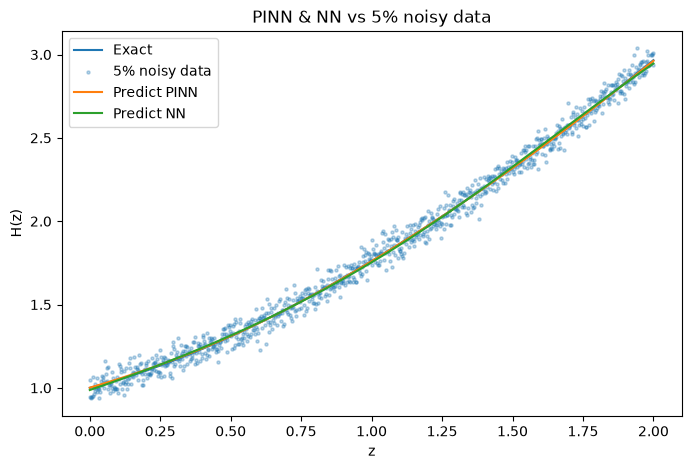

In [18]:
plt.figure(figsize=(8,5))
plt.plot (z.detach(), H_true.detach(), label = 'Exact')

plt.scatter (z.detach(), H_obs.detach(), s = 5 , alpha = 0.3, label = '5% noisy data')

plt.plot (z.detach(), H_pred_pinn.detach(), label = 'Predict PINN')

plt.plot (z.detach(), H_pred_nn.detach(), label = 'Predict NN')
plt.xlabel('z')
plt.ylabel('H(z)')
plt.title('PINN & NN vs 5% noisy data')
plt.legend()

plt.show()

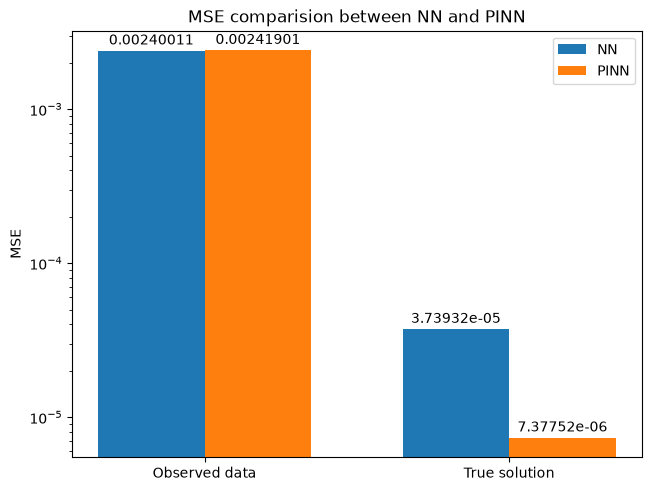

In [19]:
metrics = ('Observed data', 'True solution')
loss = {
    'NN': [mse_nn_obs.item(), mse_nn_true.item()],
    'PINN': [mse_pinn_obs.item(), mse_pinn_true.item()]
}

x = np.arange(len(metrics)) 
width = 0.35 
multiplier = 0

fig, ax = plt.subplots(layout='constrained')

for model, values in loss.items():
    offset = width * multiplier
    rects = ax.bar(x + offset, values, width, label=model)
    ax.bar_label(rects, padding=2)
    multiplier += 1

ax.set_ylabel('MSE')
ax.set_title('MSE comparision between NN and PINN')
ax.set_xticks(x + width/2, metrics)
ax.legend()
ax.set_yscale('log')
plt.show()

In [20]:
nn_mse = mse_nn_true.item()
pinn_mse =  mse_pinn_true.item()
print (nn_mse/pinn_mse)

5.068535217598253


- Although a standard neural network achieves a slightly lower MSE (Mean Squared Error) relative to the noisy observations, the PINN model yields a significantly lower MSE when compared to the true, underlying ΛCDM solution. Specifically, compared to a purely data-driven neural network, the PINN model reduces the error relative to the true solution by approximately 80%. This result demonstrates the advantage of incorporating the governing physical equation into the learning process: the physical constraint enables the PINN to avoid fitting the random fluctuations present in the noisy observations and, instead, recover a solution that is more consistent with the underlying physical model.
  
- This comparison suggests that physics-informed learning can improve the recovery of the underlying physical signal even when it does not minimize the observational-data error.




<div style="background:#DCFCE7; padding:14px;
            border-left:6px solid #16A34A;
            border-radius:8px;">
  <h2 style="color:#166534; margin:0;">
    Real Cosmic Chronometers H(z) Data
  </h2>
</div>

- In this section, the physics-informed neural network (PINN) is applied to observational Hubble parameter measurements obtained using the cosmic chronometer (CC) method. 
- The dataset contains 32 measurements and includes the redshift (z), the observed Hubble parameter H(z), its reported uncertainty sigma_Hz, reference information, and a correlation flag. The measurements cover the redshift range from approximately (z=0.07) to (z=1.965).
<br><br>

In [21]:
data = pd.read_csv("Hz_data_32points.csv")
df = pd.DataFrame(data)
df

,z,Hz,sigma_Hz,Reference,Correlated
0,0.0700,69.0,19.6,Jimenez_2003,No
1,0.0900,69.0,12.0,Simon_2005,No
2,0.1200,68.6,26.2,Jimenez_2003,No
3,0.1700,83.0,8.0,Simon_2005,No
4,0.1791,75.0,4.0,Moresco_2012,Yes
5,0.1993,75.0,5.0,Moresco_2012,Yes
6,0.2000,72.9,29.6,Jimenez_2003,No
7,0.2700,77.0,14.0,Simon_2005,No
8,0.2800,88.8,36.6,Jimenez_2003,No
9,0.3520,83.0,14.0,Moresco_2012,Yes


In [22]:
df.describe(include='all')

,z,Hz,sigma_Hz,Reference,Correlated
count,32.000000,32.000000,32.000000,32,32
unique,NaN,NaN,NaN,8,2
top,NaN,NaN,NaN,Moresco_2012,No
freq,NaN,NaN,NaN,8,17
mean,0.663991,105.700000,21.200000,NaN,NaN
std,0.512167,37.809744,13.790436,NaN,NaN
min,0.070000,68.600000,4.000000,NaN,NaN
25%,0.277500,79.925000,12.000000,NaN,NaN
50%,0.474150,91.000000,17.000000,NaN,NaN
75%,0.885000,119.000000,30.600000,NaN,NaN


In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   z           32 non-null     float64
 1   Hz          32 non-null     float64
 2   sigma_Hz    32 non-null     float64
 3   Reference   32 non-null     str    
 4   Correlated  32 non-null     str    
dtypes: float64(3), str(2)
memory usage: 1.4 KB


In [24]:
df.isna().sum().sum()

np.int64(0)

In [25]:
df.duplicated().sum()

np.int64(0)

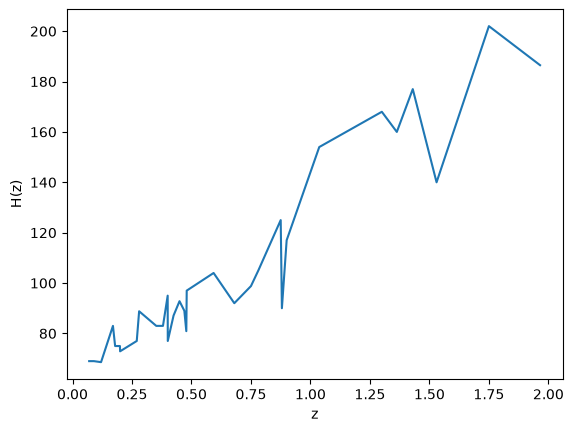

In [26]:
plt.plot(df['z'], df['Hz'])
plt.xlabel('z')
plt.ylabel('H(z)')

plt.show()

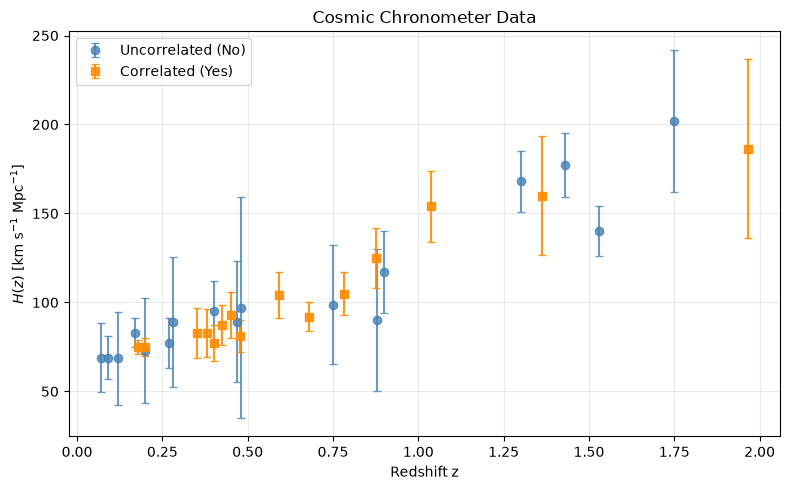

Correlated (Yes): 15
Uncorrelated (No): 17


In [27]:
correlated = df["Correlated"] == "Yes"
uncorrelated = ~correlated

plt.figure(figsize=(8, 5))

plt.errorbar(df.loc[uncorrelated, "z"],  df.loc[uncorrelated, 'Hz'], yerr=df.loc[uncorrelated, 'sigma_Hz'],
    fmt='o', color='steelblue',capsize=3, label='Uncorrelated (No)', alpha=0.8)

plt.errorbar(df.loc[correlated, 'z'], df.loc[correlated, 'Hz'], yerr=df.loc[correlated, 'sigma_Hz'],
    fmt='s', color='darkorange',capsize=3, label='Correlated (Yes)', alpha=0.9)

plt.xlabel('Redshift z')
plt.ylabel(r'$H(z)$ [km s$^{-1}$ Mpc$^{-1}$]')
plt.title('Cosmic Chronometer Data')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print('Correlated (Yes):', correlated.sum())
print('Uncorrelated (No):', uncorrelated.sum())


In [28]:
z_data = torch.tensor(df['z'].values, dtype=torch.float32).reshape(-1,1)
H_data = torch.tensor(df['Hz'].values, dtype=torch.float32)
sigma_data = torch.tensor(df['sigma_Hz'].values, dtype=torch.float32)

In [29]:
print('shape of z_data:', z_data.shape)
print('shape of H_data:', H_data.shape)
print('shape of sigma_data:', sigma_data.shape)

shape of z_data: torch.Size([32, 1])
shape of H_data: torch.Size([32])
shape of sigma_data: torch.Size([32])


## PINN Formulation


- In the analysis of real data from "cosmic chronometers," the PINN predicts the dimensionless expansion rate, $E(z)$, rather than directly predicting the Hubble parameter, $H(z)$ because $E(z)$ separates the shape of the cosmic expansion history from its overall normalization—namely, the Hubble constant ($H_0$). The two quantities are related by
$$E(z)=\frac{H(z)}{H_0},
\qquad
H(z)=H_0E(z).$$
For a spatially flat $\Lambda$CDM cosmology, the dimensionless expansion rate satisfies
$$E^2(z)=\Omega_m(1+z)^3+(1-\Omega_m).$$
Differentiating this expression with respect to redshift gives the physics-informed constraint used in the PINN:

$$2E(z)\frac{dE(z)}{dz}
-3\Omega_m(1+z)^2=0.$$
with initial condition $E(0)=1$.

- In this approach, both $H_0$ and $\Omega_m$ were introduced as trainable parameters of the PINN. Instead of keeping these parameters fixed at predefined values, we allowed the model to learn them during training by minimizing a combined loss function based on both physics and data fitting. This enables the PINN to reconstruct the expansion history while simultaneously estimating cosmological parameters from cosmic chronometer observations.

<br><br>

In [30]:
z_data = torch.tensor(df['z'].values, dtype=torch.float32).reshape(-1,1)
z_data.requires_grad_(True)
H_data = torch.tensor(df['Hz'].values, dtype=torch.float32).reshape(-1,1)
sigma_data = torch.tensor(df['sigma_Hz'].values, dtype=torch.float32).reshape(-1,1)
class PINN_cc_data(nn.Module):
    def __init__(self):
        super().__init__()
        self.omega= nn.Parameter(torch.tensor(-0.8473))
        self.log_H0 = nn.Parameter(torch.log(torch.tensor(70.0)))
        self.layer1 = nn.Linear(1,19)
        self.tanh = nn.Tanh()
        self.layer2 = nn.Linear(19,1)
    
    def omega_m(self):
        return torch.sigmoid(self.omega)

    def H0(self):
        return torch.exp(self.log_H0)

    def forward(self,z):
        output = self.layer1(z)
        output = self.tanh(output)
        E = self.layer2(output)
        return E


model_pinn_ccdata = PINN_cc_data()
optimizer_cc = torch.optim.Adam(model_pinn_ccdata.parameters(), lr=0.01)
z0 = torch.tensor([[0.0]])
lambda_r = 1.0
lambda_ic = 10.0
lambda_data = 1.0


for epoch in range(2000):
    E_pred = model_pinn_ccdata(z_data)
    dE_dz = torch.autograd.grad(
        outputs = E_pred,
        inputs = z_data,
        create_graph=True,
        grad_outputs=torch.ones_like(E_pred))[0]
    residual = 2 * (E_pred * dE_dz) -3 * model_pinn_ccdata.omega_m() * (1 + z_data)**2
    loss_r = torch.mean(residual**2)
    E0_pred = model_pinn_ccdata (z0)
    loss_ic = torch.mean((E0_pred - 1)**2)
    H_pred = E_pred * model_pinn_ccdata.H0()
    loss_data = torch.mean(((H_pred - H_data)/sigma_data)**2)
    loss_cc = lambda_r * loss_r +lambda_ic *  loss_ic + lambda_data * loss_data
    optimizer_cc.zero_grad()
    loss_cc.backward()
    optimizer_cc.step()
    if epoch %200 ==0:
         print(
            f"epoch = {epoch:4d} | "
            f"total = {loss_cc.item():.5f} | "
            f"L_phys = {loss_r.item():.5f} | "
            f"L_IC = {loss_ic.item():.5f} | "
            f"L_data = {loss_data.item():.5f} | "
            f"Omega_m = {model_pinn_ccdata.omega_m().item():.5f} | "
            f"H0 = {model_pinn_ccdata.H0().item():.3f}"  )

    

epoch =    0 | total = 167.45058 | L_phys = 10.11476 | L_IC = 2.48642 | L_data = 132.47163 | Omega_m = 0.29790 | H0 = 69.303
epoch =  200 | total = 1.38031 | L_phys = 0.61275 | L_IC = 0.01013 | L_data = 0.66630 | Omega_m = 0.16809 | H0 = 74.295
epoch =  400 | total = 0.84967 | L_phys = 0.14753 | L_IC = 0.00714 | L_data = 0.63075 | Omega_m = 0.16036 | H0 = 76.567
epoch =  600 | total = 0.62379 | L_phys = 0.06192 | L_IC = 0.00381 | L_data = 0.52382 | Omega_m = 0.18943 | H0 = 76.766
epoch =  800 | total = 0.56309 | L_phys = 0.06074 | L_IC = 0.00206 | L_data = 0.48175 | Omega_m = 0.21928 | H0 = 74.622
epoch = 1000 | total = 0.52985 | L_phys = 0.05442 | L_IC = 0.00116 | L_data = 0.46382 | Omega_m = 0.24137 | H0 = 72.980
epoch = 1200 | total = 0.50938 | L_phys = 0.04659 | L_IC = 0.00069 | L_data = 0.45589 | Omega_m = 0.25810 | H0 = 71.797
epoch = 1400 | total = 0.49515 | L_phys = 0.03847 | L_IC = 0.00042 | L_data = 0.45247 | Omega_m = 0.27151 | H0 = 70.886
epoch = 1600 | total = 0.48477 | L_

In [31]:
print ( f"epoch = {epoch:4d} | "
            f"total = {loss_cc.item():.5f} | "  f"Omega_m = {model_pinn_ccdata.omega_m().item():.5f} | "
            f"H0 = {model_pinn_ccdata.H0().item():.3f}")

epoch = 1999 | total = 0.47135 | Omega_m = 0.29866 | H0 = 69.182


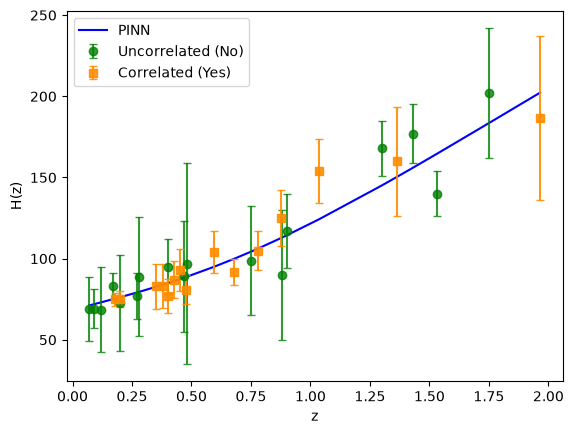

In [32]:
z_test =  torch.tensor(df['z'].values, dtype=torch.float32).reshape(-1,1)
with torch.no_grad():
    E_pred = model_pinn_ccdata(z_test)
    H_pred = E_pred * model_pinn_ccdata.H0()


plt.plot(z_test.numpy(), H_pred.numpy(), color='blue', label='PINN')

plt.errorbar(df.loc[uncorrelated, 'z'],  df.loc[uncorrelated, 'Hz'], yerr=df.loc[uncorrelated, 'sigma_Hz'],
    fmt='o', color='green',capsize=3, label='Uncorrelated (No)', alpha=0.8)

plt.errorbar(df.loc[correlated, 'z'], df.loc[correlated, 'Hz'], yerr=df.loc[correlated, 'sigma_Hz'],
    fmt='s', color='darkorange', capsize=3,label='Correlated (Yes)', alpha=0.9)

plt.xlabel('z')
plt.ylabel('H(z)')
plt.legend()

plt.show()


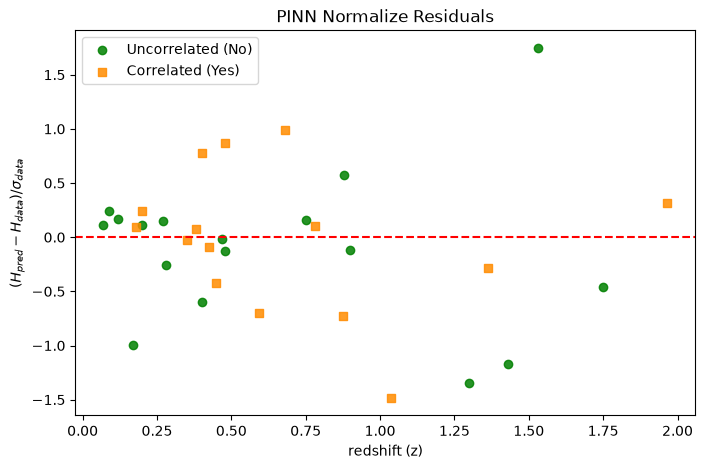

In [33]:
z_test =  torch.tensor(df['z'].values, dtype=torch.float32).reshape(-1,1)
with torch.no_grad():
    E_pred = model_pinn_ccdata(z_test)
    H_pred = E_pred * model_pinn_ccdata.H0()
    
r = (H_pred - H_data)/sigma_data
correlated =torch.tensor( df["Correlated"]=='Yes').reshape(-1,1)

plt.figure(figsize=(8,5))
plt.scatter (z_test[uncorrelated].numpy(), r[uncorrelated].numpy(), color='green', marker='o',
    label='Uncorrelated (No)', alpha=0.85)

plt.scatter (z_test[correlated].numpy(), r[correlated].numpy(), color='darkorange', marker='s',
    label='Correlated (Yes)', alpha=0.85)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('redshift (z)')
plt.ylabel('$(H_{pred}-H_{data})/{\sigma_{data}}$')
plt.title('PINN Normalize Residuals')
plt.legend()

plt.show()

In [34]:
chi_squared = torch.sum(r**2).item()
reduced_chi_squared = chi_squared/(len(r)-2)
print('Chi_squared:', chi_squared)
print('Reduced_chi_squared:', reduced_chi_squared)

Chi_squared: 14.415842056274414
Reduced_chi_squared: 0.4805280685424805


<div style="background:#DCFCE7; padding:14px;
            border-left:6px solid #16A34A;
            border-radius:8px;">
  <h2 style="color:#166534; margin:0;">
    Conclusion
  </h2>
</div>

In this project, neural networks and Physics-Informed Neural Networks (PINNs) were employed to reconstruct the cosmological expansion history $H(z)$ within the framework of the $\Lambda$CDM model.

In an experiment using synthetic data, the PINN model achieved a lower mean squared error relative to the underlying true solution compared to a conventional neural network, this demonstrates that incorporating physical constraints can improve reconstruction in the presence of noise.

When applying this method to data obtained from "Cosmic Chronometer" observations, the following parameter values were estimated:

$\Omega_m \approx 0.30652$

$H_0 \approx 68.846 \text{ km s}^{-1} \text{ Mpc}^{-1}$

These estimates depend on the chosen model, the loss function, data uncertainties, and the training process. 
<br><br>